# **Classification Project: German Credit Risk Prediction**

# **Marks: 100**

Welcome to the classification project.

In this project, you will build machine learning models to predict whether a credit applicant is a **good** or **bad** credit risk.

---
## **Objective**
---
The objective of this project is to:
- Perform exploratory data analysis (EDA)
- Apply proper preprocessing using Pipelines
- Build and tune classification models
- Compare models and justify a final recommendation


---
## **Dataset Description**
---
We use the **German Credit dataset (credit-g, OpenML id 31)**.

Each row represents a loan applicant described by a mixture of numerical and categorical features.

Target variable:
- `good` = 0
- `bad` = 1

You will load the dataset using `fetch_openml`.


## **Importing the necessary libraries**

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer, make_column_selector as selector
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay

np.random.seed(42)

In [58]:
plt.style.use('seaborn-v0_8-dark')
C_GOOD = '#A080C0' # Darker purple
C_BAD   = '#4CAF98' # Darker teal/green
C_ACC   = '#A8D8C8'
COLORS = [C_GOOD, C_BAD]

cm_cmap = LinearSegmentedColormap.from_list("custom_cmap", ["#FFFFFF", "#4CAF98"])

## **Loading the Dataset**

In [59]:
#Loading the dataset using fetch_openml
Xy = fetch_openml(data_id=31, as_frame=True)
X = Xy.data
y_raw = Xy.target
X.head()

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,4,real estate,67,none,own,2,skilled,1,yes,yes
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,2,real estate,22,none,own,1,skilled,1,none,yes
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,4,life insurance,45,none,for free,1,skilled,2,none,yes
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,4,no known property,53,none,for free,2,skilled,2,none,yes


In [60]:
print(y_raw.unique())
display(y_raw.head())

['good', 'bad']
Categories (2, object): ['bad', 'good']


,class
0,good
1,bad
2,good
3,good
4,bad


In [61]:
#Mapping target labels to integers (0,1)
y = y_raw.map({'good': 0, 'bad': 1})
print('Mapped target labels to y:')
display(y.head())

Mapped target labels to y:


,class
0,0
1,1
2,0
3,0
4,1


---
## **Data Overview**
---
- Number of observations
- Number of features
- Class distribution
- Check for missing values


In [62]:
print('Shape of X:', X.shape)
print('Shape of y:', y.shape)

Shape of X: (1000, 20)
Shape of y: (1000,)


In [63]:
print('\nFirst 5 rows of X:')
display(X.head())


First 5 rows of X:


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,4,real estate,67,none,own,2,skilled,1,yes,yes
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,2,real estate,22,none,own,1,skilled,1,none,yes
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,4,life insurance,45,none,for free,1,skilled,2,none,yes
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,4,no known property,53,none,for free,2,skilled,2,none,yes


In [64]:
#Descrpition of numerical data
display(X.describe())

,duration,credit_amount,installment_commitment,residence_since,age,existing_credits,num_dependents
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.903000,3271.258000,2.973000,2.845000,35.546000,1.407000,1.155000
std,12.058814,2822.736876,1.118715,1.103718,11.375469,0.577654,0.362086
min,4.000000,250.000000,1.000000,1.000000,19.000000,1.000000,1.000000
25%,12.000000,1365.500000,2.000000,2.000000,27.000000,1.000000,1.000000
50%,18.000000,2319.500000,3.000000,3.000000,33.000000,1.000000,1.000000
75%,24.000000,3972.250000,4.000000,4.000000,42.000000,2.000000,1.000000
max,72.000000,18424.000000,4.000000,4.000000,75.000000,4.000000,2.000000


In [65]:
print('\nMissing values in X:')
display(X.isnull().sum().sort_values(ascending=False))
print('\nMissing values in y:')
display(y.isnull().sum())


Missing values in X:


,0
checking_status,0
duration,0
credit_history,0
purpose,0
credit_amount,0
savings_status,0
employment,0
installment_commitment,0
personal_status,0
other_parties,0



Missing values in y:


np.int64(0)

---
## **Exploratory Data Analysis (EDA)**
---
*   Visualizing class distribution - identification of imbalances
*   Visualizing the distribution of key numerical features
*   Exploration of a cateforical feature and its relationship to the target



Class distribution of y:
class
0    0.7
1    0.3
Name: proportion, dtype: float64


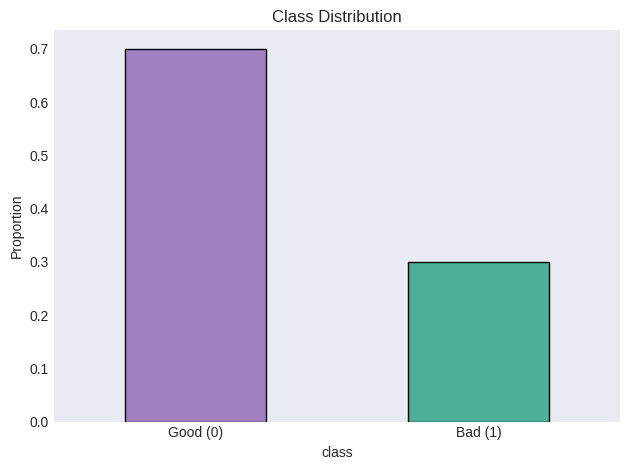

In [66]:
#Plotting class distribution

print('\nClass distribution of y:')
counts = y.value_counts(normalize=True)
print(counts)
counts.plot(kind='bar', color=COLORS, edgecolor='black')
plt.xticks([0,1], ['Good (0)', 'Bad (1)'], rotation=0)
plt.title('Class Distribution')
plt.ylabel('Proportion')
plt.tight_layout()
plt.show()

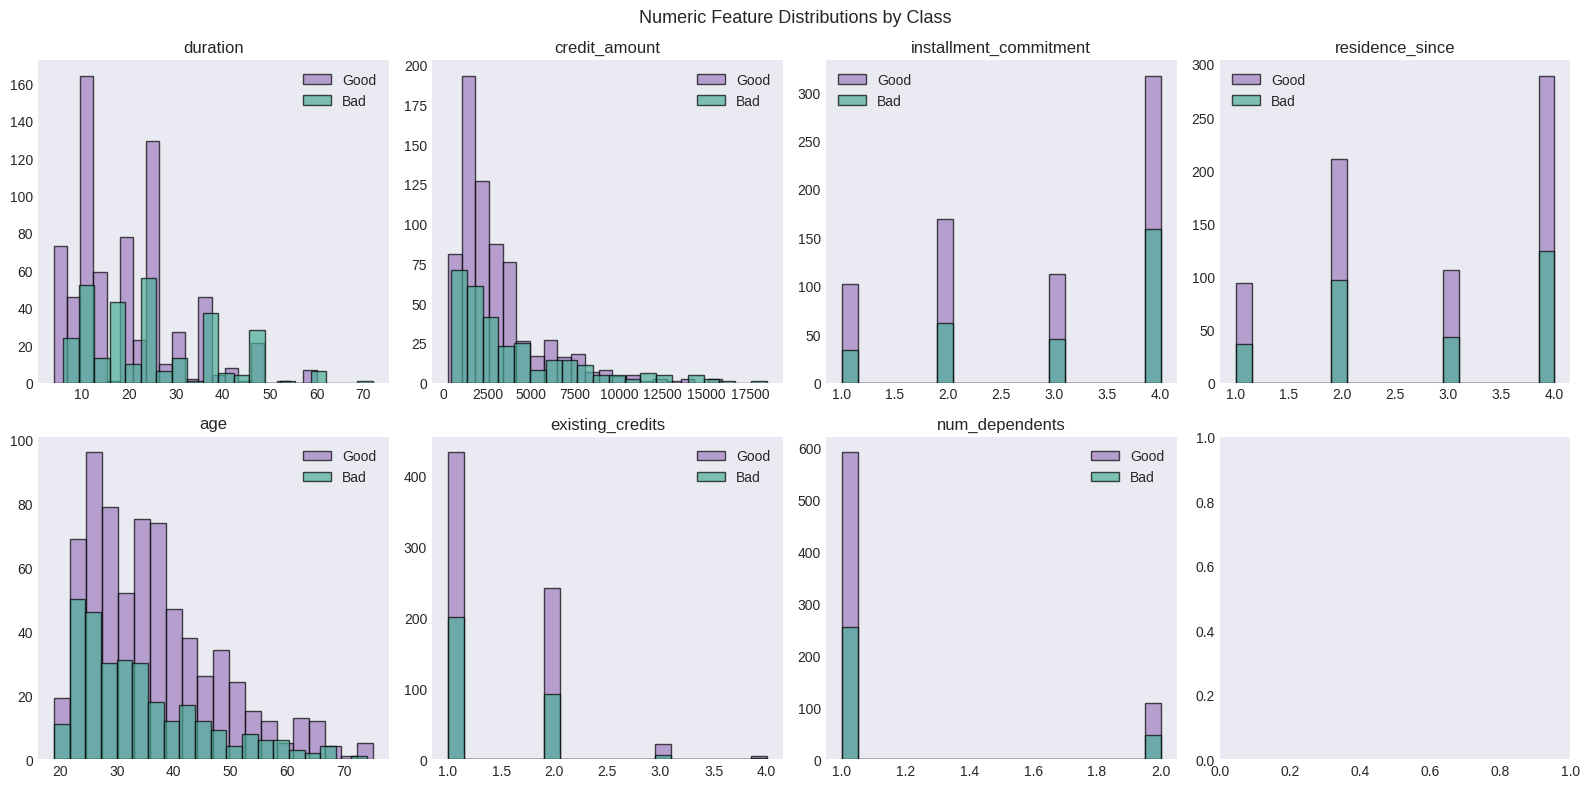

In [67]:
#Plotting histograms for numeric features
num_cols = X.select_dtypes(include='number').columns

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols[:8]):
    axes[i].hist(X[col][y==0], alpha=0.7, label='Good', color=C_GOOD, bins=20, edgecolor="black")
    axes[i].hist(X[col][y==1], alpha=0.7, label='Bad',  color=C_BAD,  bins=20, edgecolor="black")
    axes[i].set_title(col)
    axes[i].legend()

plt.suptitle('Numeric Feature Distributions by Class', fontsize=13)
plt.tight_layout()
plt.show()

/tmp/ipykernel_535/1418673387.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([data_good, data_bad], labels=['Good', 'Bad'], patch_artist=True)
/tmp/ipykernel_535/1418673387.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([data_good, data_bad], labels=['Good', 'Bad'], patch_artist=True)
/tmp/ipykernel_535/1418673387.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([data_good, data_bad], labels=['Good', 'Bad'], patch_artist=True)


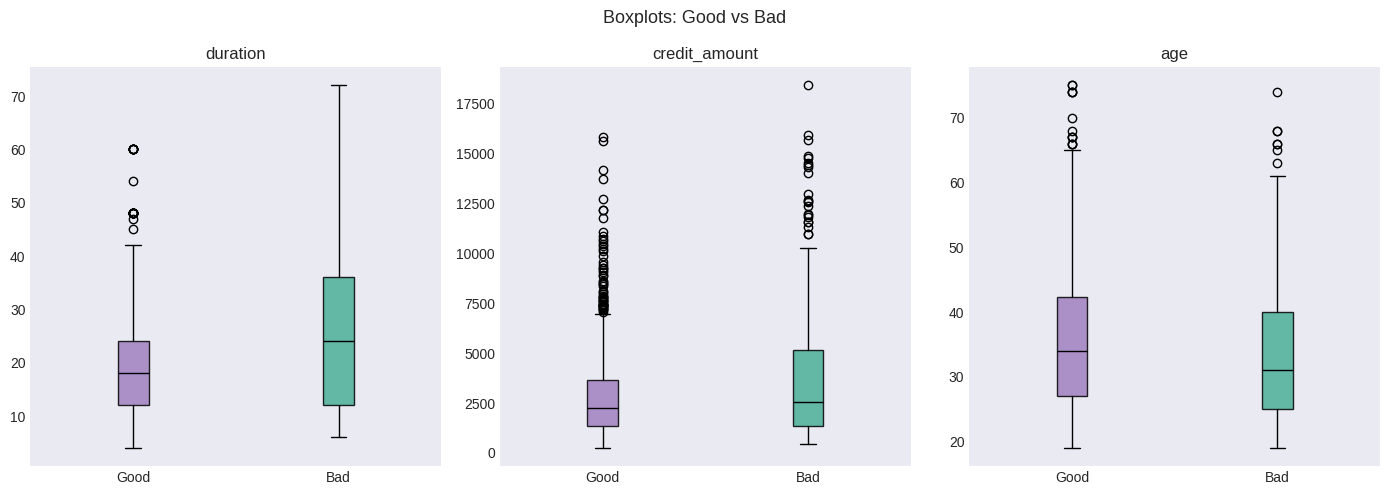

In [68]:
#Boxplots of some numeric features by class
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for ax, col in zip(axes, ['duration', 'credit_amount', 'age']):
    data_good = X[col][y==0]
    data_bad  = X[col][y==1]
    bp = ax.boxplot([data_good, data_bad], labels=['Good', 'Bad'], patch_artist=True)
    for patch, color in zip(bp['boxes'], COLORS):
        patch.set_facecolor(color)
        patch.set_alpha(0.85)
        patch.set_edgecolor('black')
    for element in ['whiskers', 'caps', 'medians']:
        plt.setp(bp[element], color='black')
    plt.setp(bp['fliers'], markeredgecolor='black')
    ax.set_title(col)

plt.suptitle('Boxplots: Good vs Bad', fontsize=13)
plt.tight_layout()
plt.show()

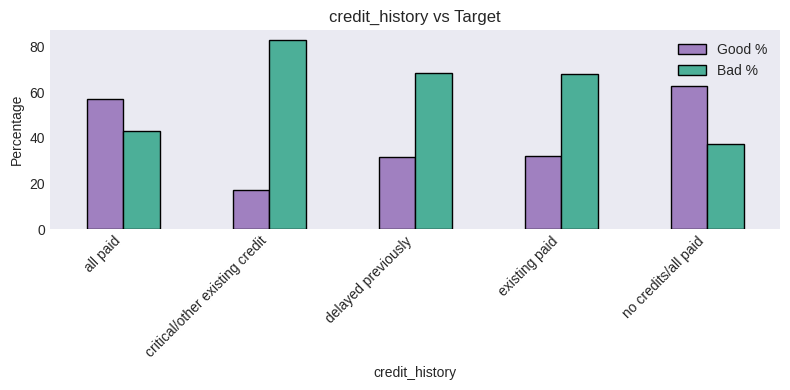

In [69]:
#Exploration of one categorical feature vs target
cat_col = 'credit_history'
ct = pd.crosstab(X[cat_col], y, normalize='index') * 100
ct.columns = ['Good %', 'Bad %']

ct.plot(kind='bar', figsize=(8,4), color=COLORS, edgecolor='black')
plt.title(f'{cat_col} vs Target')
plt.ylabel('Percentage')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

---
## **Data Preprocessing**
---
- Split into train and test sets (use stratification)
- Keep the test set untouched until final evaluation
- Use Pipeline + ColumnTransformer
- Scale numerical features
- One-hot encode categorical features


In [70]:
#Train/test split with stratification - using 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
#stratify=y - the distribution of the dataset is maintained across the split as well

In [71]:
#Definition of numerical and categorical features
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include='category').columns.tolist()

print("Numeric features:",    numeric_features)
print("Categorical features:", categorical_features)

#Numeric pipeline: transforms the numeric features, using a z-score normalization
numeric_pipeline = Pipeline([
    ('scaler', StandardScaler())
])

#Categorical features: transforms cat data to num - creates a numeric array of 0s and a 1
categorical_pipeline = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

#Combination of piplines
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

Numeric features: ['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']
Categorical features: ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']


---
## **Conceptual Question: Perceptron (No Implementation)**
---
1. What assumptions does the Perceptron make?

The Perceptron assumes that the data is linearly separable, meaning that a single hyperplane can divide the dataset into two classes.

2. When is convergence guaranteed?

If and only if the data is linearly separable. In that case, the algorithm makes at most (R/γ)² mistakes, where R is the maximum norm of any input vector and γ is the margin of the dataset.

3. Is it likely appropriate for this dataset? Why or why not?

The Perceptron is probably not appropriate for this dataset. Real-world credit data is unlikely to be linearly separable, since good and bad applicants can overlap significantly across features (as also seen in the EDA). If the data is not linearly separable, the Perceptron never converges and cycles indefinitely.

---
## **Model Building: Linear Models**
---
You will build and tune:
- Logistic Regression
- Linear SVM

Use cross-validation on the training set to tune `C`.


Best C for Logistic Regression: 0.615848211066026

Logistic Regression Training Set Accuracy: 0.7837
Logistic Regression Test Set Metrics:
Accuracy: 0.7850
Precision: 0.6809
Recall: 0.5333
F1-Score: 0.5981


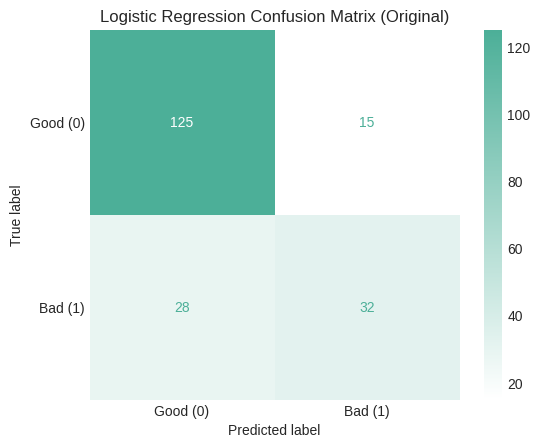

In [72]:
logistic_regression_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42,solver='liblinear'))
])
#solver=liblinear: algorithm recommended for optimizing the logistic regression

# Define parameter grid for C used for cross validation - controls trade-off (inverse of regularization strength)
param_grid_lr = {
    'classifier__C': np.logspace(-4, 4, 20)
}

#StratifiedKFold: used for cross validation - divides the training to k folds
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# Set up GridSearchCV: used to find the best hyperparameters
grid_search_lr = GridSearchCV(logistic_regression_pipeline, param_grid_lr, cv=skf, scoring='f1', n_jobs=-1)

# Fit: trains the pipeline across all C values and corss-validation folds
grid_search_lr.fit(X_train, y_train)

# Gets model with best f1 score
best_lr_model = grid_search_lr.best_estimator_

print("Best C for Logistic Regression:", grid_search_lr.best_params_['classifier__C'])

# Evaluating on training set
y_pred_train_lr = best_lr_model.predict(X_train)
accuracy_train_lr = accuracy_score(y_train, y_pred_train_lr)

# Evaluating on test set
y_pred_lr = best_lr_model.predict(X_test)

accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)

print(f"\nLogistic Regression Training Set Accuracy: {accuracy_train_lr:.4f}")
print(f"Logistic Regression Test Set Metrics:")
print(f"Accuracy: {accuracy_lr:.4f}")
print(f"Precision: {precision_lr:.4f}")
print(f"Recall: {recall_lr:.4f}")
print(f"F1-Score: {f1_lr:.4f}")

cm_lr = confusion_matrix(y_test, y_pred_lr, labels=best_lr_model.classes_)
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=['Good (0)', 'Bad (1)'])
disp_lr.plot(cmap=cm_cmap)
plt.title('Logistic Regression Confusion Matrix (Original)')
plt.show()

Best C for Linear SVM: 0.615848211066026

Linear SVM Training Set Accuracy: 0.7875
Linear SVM Test Set Metrics:
Accuracy: 0.7750
Precision: 0.6415
Recall: 0.5667
F1-Score: 0.6018


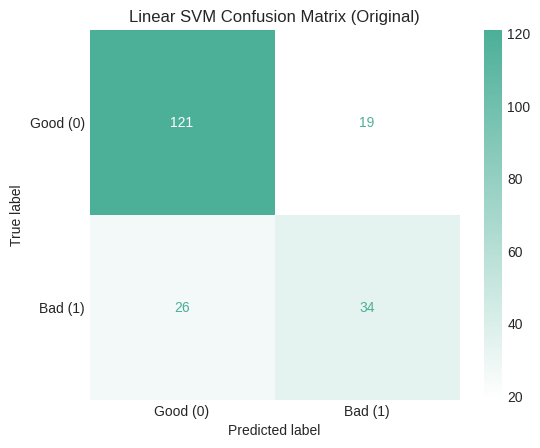

In [73]:
linear_svm_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LinearSVC(random_state=42, dual=False)) # dual=False recommended for n_samples > n_features
])

param_grid_svm = {
    'classifier__C': np.logspace(-4, 4, 20)
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search_svm = GridSearchCV(linear_svm_pipeline, param_grid_svm, cv=skf, scoring='f1', n_jobs=-1)

grid_search_svm.fit(X_train, y_train)

best_svm_model = grid_search_svm.best_estimator_

print("Best C for Linear SVM:", grid_search_svm.best_params_['classifier__C'])

y_pred_train_svm = best_svm_model.predict(X_train)
accuracy_train_svm = accuracy_score(y_train, y_pred_train_svm)

y_pred_svm = best_svm_model.predict(X_test)

accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm)
recall_svm = recall_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm)

print(f"\nLinear SVM Training Set Accuracy: {accuracy_train_svm:.4f}")
print(f"Linear SVM Test Set Metrics:")
print(f"Accuracy: {accuracy_svm:.4f}")
print(f"Precision: {precision_svm:.4f}")
print(f"Recall: {recall_svm:.4f}")
print(f"F1-Score: {f1_svm:.4f}")

cm_svm = confusion_matrix(y_test, y_pred_svm, labels=best_svm_model.classes_)
disp_svm = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=['Good (0)', 'Bad (1)'])
disp_svm.plot(cmap=cm_cmap)
plt.title('Linear SVM Confusion Matrix (Original)')
plt.show()

---
## **Model Building: k-Nearest Neighbors (kNN)**
---
Tune the number of neighbors and evaluate performance.


Best n_neighbors for kNN: 5

kNN Training Set Accuracy: 0.8213
kNN Test Set Metrics:
Accuracy: 0.7250
Precision: 0.5676
Recall: 0.3500
F1-Score: 0.4330


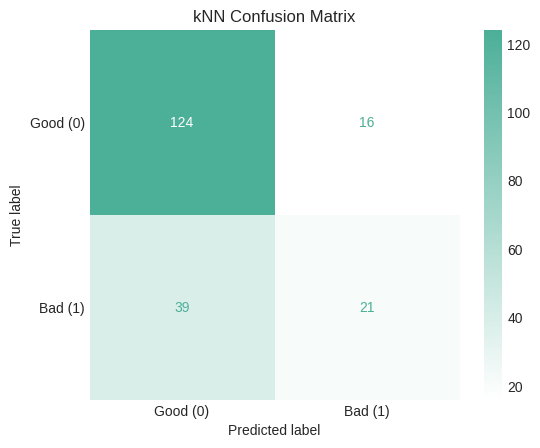

In [74]:
knn_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier())
])

#Trying odd numbers for n_neighbors to avoid ties in binary classification
param_grid_knn = {
    'classifier__n_neighbors': range(3, 31,2) # e.g. 3, 5, ..., 29
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search_knn = GridSearchCV(knn_pipeline, param_grid_knn, cv=skf, scoring='f1', n_jobs=-1)

grid_search_knn.fit(X_train, y_train)

best_knn_model = grid_search_knn.best_estimator_

print("Best n_neighbors for kNN:", grid_search_knn.best_params_['classifier__n_neighbors'])

y_pred_train_knn = best_knn_model.predict(X_train)
accuracy_train_knn = accuracy_score(y_train, y_pred_train_knn)

y_pred_knn = best_knn_model.predict(X_test)

accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn)
recall_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)

print(f"\nkNN Training Set Accuracy: {accuracy_train_knn:.4f}")
print(f"kNN Test Set Metrics:")
print(f"Accuracy: {accuracy_knn:.4f}")
print(f"Precision: {precision_knn:.4f}")
print(f"Recall: {recall_knn:.4f}")
print(f"F1-Score: {f1_knn:.4f}")

cm_knn = confusion_matrix(y_test, y_pred_knn, labels=best_knn_model.classes_)
disp_knn = ConfusionMatrixDisplay(confusion_matrix=cm_knn, display_labels=['Good (0)', 'Bad (1)'])
disp_knn.plot(cmap=cm_cmap)
plt.title('kNN Confusion Matrix')
plt.show()


kNN (k=1) Training Set Accuracy: 1.0000
kNN (k=1) Test Set Metrics:
Accuracy: 0.7300
Precision: 0.5556
Recall: 0.5000
F1-Score: 0.5263


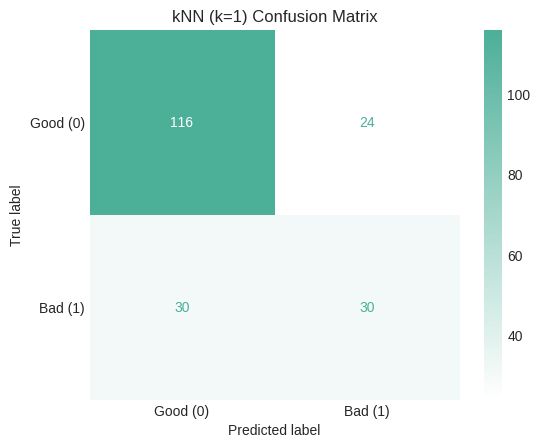

In [75]:
knn_pipeline_k1 = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=1))
])

knn_pipeline_k1.fit(X_train, y_train)

y_pred_train_knn_k1 = knn_pipeline_k1.predict(X_train)
accuracy_train_knn_k1 = accuracy_score(y_train, y_pred_train_knn_k1)

y_pred_knn_k1 = knn_pipeline_k1.predict(X_test)

accuracy_knn_k1 = accuracy_score(y_test, y_pred_knn_k1)
precision_knn_k1 = precision_score(y_test, y_pred_knn_k1)
recall_knn_k1 = recall_score(y_test, y_pred_knn_k1)
f1_knn_k1 = f1_score(y_test, y_pred_knn_k1)

print(f"\nkNN (k=1) Training Set Accuracy: {accuracy_train_knn_k1:.4f}")
print(f"kNN (k=1) Test Set Metrics:")
print(f"Accuracy: {accuracy_knn_k1:.4f}")
print(f"Precision: {precision_knn_k1:.4f}")
print(f"Recall: {recall_knn_k1:.4f}")
print(f"F1-Score: {f1_knn_k1:.4f}")

cm_knn_k1 = confusion_matrix(y_test, y_pred_knn_k1, labels=[0, 1])  # fixed
disp_knn_k1 = ConfusionMatrixDisplay(confusion_matrix=cm_knn_k1, display_labels=['Good (0)', 'Bad (1)'])
disp_knn_k1.plot(cmap=cm_cmap)
plt.title('kNN (k=1) Confusion Matrix')
plt.show()

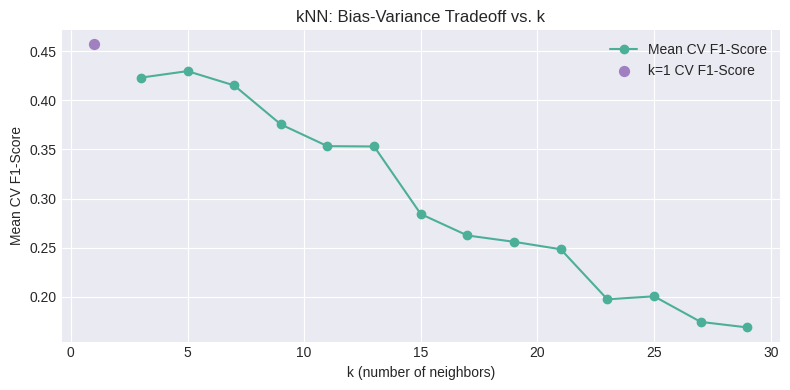

In [76]:
k_values = range(3,31,2)
cv_scores = []

for k in k_values:
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', KNeighborsClassifier(n_neighbors=k))
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=skf, scoring='f1')
    cv_scores.append(scores.mean())

plt.figure(figsize=(8, 4))
plt.plot(k_values, cv_scores, marker='o', color=C_BAD, label='Mean CV F1-Score')  # ← this was missing
scores_k1 = cross_val_score(knn_pipeline_k1, X_train, y_train, cv=skf, scoring='f1')
plt.scatter(1, scores_k1.mean(), color=C_GOOD, s=50, zorder=5, label='k=1 CV F1-Score')
plt.xlabel('k (number of neighbors)')
plt.ylabel('Mean CV F1-Score')
plt.title('kNN: Bias-Variance Tradeoff vs. k')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

---
## **Model Performance Comparison**
---
- Compare Accuracy, Precision, Recall, and F1-score
- Interpret confusion matrices
- Which model performs best and why?


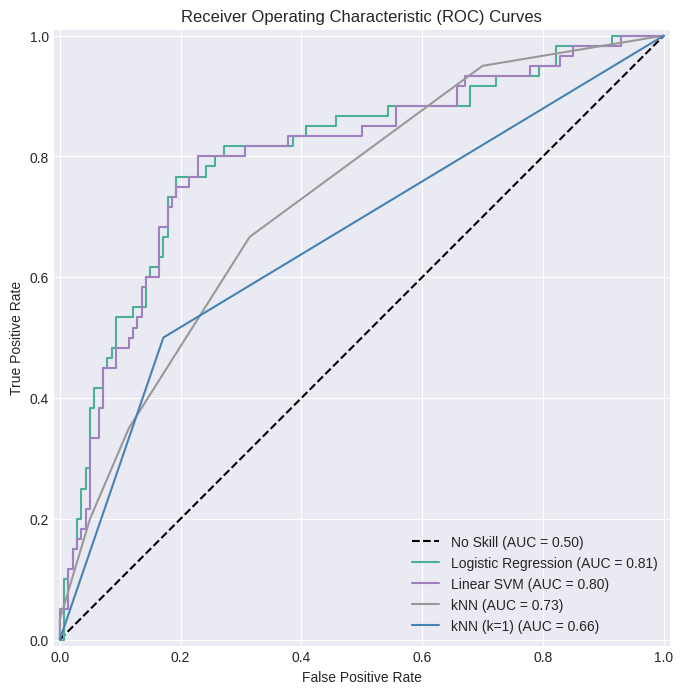

In [77]:
plt.figure(figsize=(10, 8))
plt.plot([0, 1], [0, 1], 'k--', label='No Skill (AUC = 0.50)') # Baseline

# Plot ROC curve for Logistic Regression
RocCurveDisplay.from_estimator(best_lr_model, X_test, y_test,
                               name='Logistic Regression',
                               ax=plt.gca(), color=C_BAD)

# Plot ROC curve for Linear SVM
RocCurveDisplay.from_estimator(best_svm_model, X_test, y_test,
                               name='Linear SVM',
                               ax=plt.gca(), color=C_GOOD)

# Plot ROC curve for kNN
RocCurveDisplay.from_estimator(best_knn_model, X_test, y_test,
                               name='kNN',
                               ax=plt.gca(), color='#999999')

# Plot ROC curve for kNN (k=1)
RocCurveDisplay.from_estimator(knn_pipeline_k1, X_test, y_test,
                               name='kNN (k=1)',
                               ax=plt.gca(), color='#4682B4')

plt.title('Receiver Operating Characteristic (ROC) Curves')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [78]:
metrics = {
    'Model': ['Logistic Regression', 'Linear SVM', 'kNN', 'kNN (k=1)'],
    'Train Accuracy': [accuracy_train_lr, accuracy_train_svm, accuracy_train_knn, accuracy_train_knn_k1],
    'Test Accuracy': [accuracy_lr, accuracy_svm, accuracy_knn, accuracy_knn_k1],
    'Precision': [precision_lr, precision_svm, precision_knn, precision_knn_k1],
    'Recall': [recall_lr, recall_svm, recall_knn, recall_knn_k1],
    'F1-Score': [f1_lr, f1_svm, f1_knn, f1_knn_k1]
}

metrics_df = pd.DataFrame(metrics)
metrics_df = metrics_df.set_index('Model')
metrics_df_rounded = metrics_df.round(4)

print("\nModel Performance Comparison:")
display(metrics_df_rounded)


Model Performance Comparison:


,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score
Model,,,,,
Logistic Regression,0.7837,0.785,0.6809,0.5333,0.5981
Linear SVM,0.7875,0.775,0.6415,0.5667,0.6018
kNN,0.8212,0.725,0.5676,0.3500,0.4330
kNN (k=1),1.0000,0.730,0.5556,0.5000,0.5263


---
## **Ways to Improve the Models**
---


Best C: 0.615848211066026
Train Accuracy: 0.7200
Test Accuracy:  0.7200
Precision:      0.5208
Recall:         0.8333
F1-Score:       0.6410


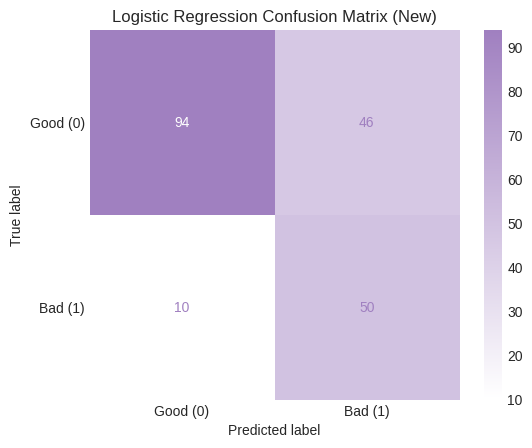

In [83]:
lr_pipeline_new = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        random_state=42,
        solver='liblinear',
        class_weight={0: 1, 1: 3} #change
    ))
])

param_grid_lr_new = {'classifier__C': np.logspace(-4, 4, 20)}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search_lr_new = GridSearchCV(lr_pipeline_new, param_grid_lr_new, cv=skf, scoring='f1', n_jobs=-1)
grid_search_lr_new.fit(X_train, y_train)
best_lr_model_new = grid_search_lr_new.best_estimator_
y_pred_train_lr_new = best_lr_model_new.predict(X_train)
y_pred_lr_new = best_lr_model_new.predict(X_test)

accuracy_train_lr_new = accuracy_score(y_train, y_pred_train_lr_new)
accuracy_lr_new = accuracy_score(y_test, y_pred_lr_new)
precision_lr_new = precision_score(y_test, y_pred_lr_new)
recall_lr_new = recall_score(y_test, y_pred_lr_new)
f1_lr_new = f1_score(y_test, y_pred_lr_new)

print(f"Best C: {grid_search_lr_new.best_params_['classifier__C']}")
print(f"Train Accuracy: {accuracy_train_lr_new:.4f}")
print(f"Test Accuracy:  {accuracy_lr_new:.4f}")
print(f"Precision:      {precision_lr_new:.4f}")
print(f"Recall:         {recall_lr_new:.4f}")
print(f"F1-Score:       {f1_lr_new:.4f}")

cm_cmap_improved = LinearSegmentedColormap.from_list("svm_improved_cmap", ["#FFFFFF", C_GOOD])
cm_lr = confusion_matrix(y_test, y_pred_lr_new, labels=best_lr_model_new.classes_)
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=['Good (0)', 'Bad (1)'])
disp_lr.plot(cmap=cm_cmap_improved)
plt.title('Logistic Regression Confusion Matrix (New)')
plt.show()

Best C: 0.03359818286283781
Train Accuracy: 0.7150
Test Accuracy:  0.7150
Precision:      0.5155
Recall:         0.8333
F1-Score:       0.6369


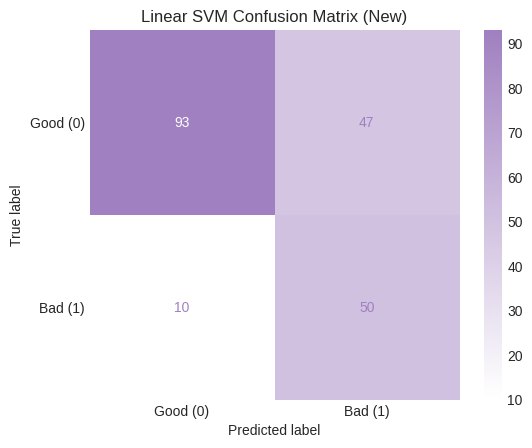

In [82]:
svm_pipeline_new = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LinearSVC(
        random_state=42,
        dual=False,
        class_weight={0: 1, 1: 3},
    ))
])

param_grid_svm_new = {'classifier__C': np.logspace(-4, 4, 20)}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search_svm_new = GridSearchCV(svm_pipeline_new, param_grid_svm_new, cv=skf, scoring='f1', n_jobs=-1)
grid_search_svm_new.fit(X_train, y_train)
best_svm_model_new = grid_search_svm_new.best_estimator_
y_pred_train_svm_new = best_svm_model_new.predict(X_train)
y_pred_svm_new = best_svm_model_new.predict(X_test)

accuracy_train_svm_new = accuracy_score(y_train, y_pred_train_svm_new)
accuracy_svm_new = accuracy_score(y_test, y_pred_svm_new)
precision_svm_new = precision_score(y_test, y_pred_svm_new)
recall_svm_new = recall_score(y_test, y_pred_svm_new)
f1_svm_new = f1_score(y_test, y_pred_svm_new)

print(f"Best C: {grid_search_svm_new.best_params_['classifier__C']}")
print(f"Train Accuracy: {accuracy_train_svm_new:.4f}")
print(f"Test Accuracy:  {accuracy_svm_new:.4f}")
print(f"Precision:      {precision_svm_new:.4f}")
print(f"Recall:         {recall_svm_new:.4f}")
print(f"F1-Score:       {f1_svm_new:.4f}")

cm_svm = confusion_matrix(y_test, y_pred_svm_new, labels=best_svm_model_new.classes_)
disp_svm = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=['Good (0)', 'Bad (1)'])
disp_svm.plot(cmap=cm_cmap_improved)
plt.title('Linear SVM Confusion Matrix (New)')
plt.show()

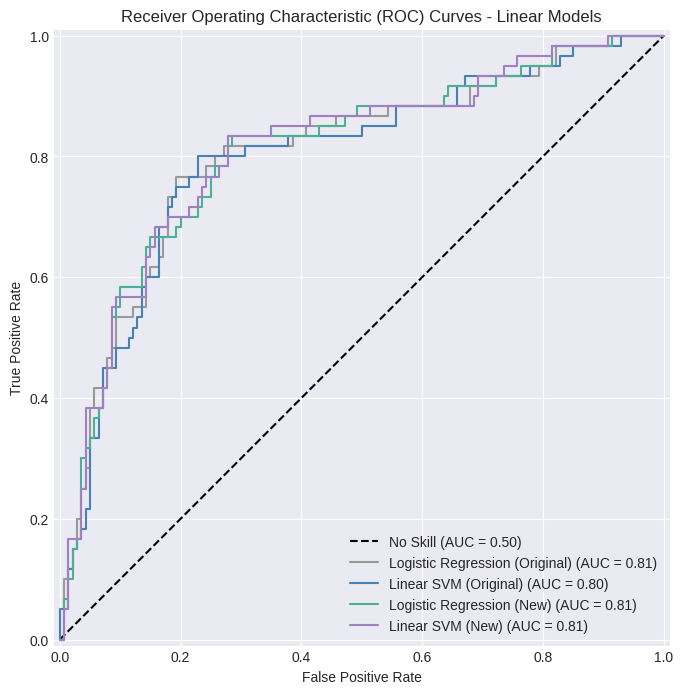


Comprehensive Model Performance Comparison (Linear Models Only):


,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score
Model,,,,,
Logistic Regression (Original),0.7837,0.785,0.6809,0.5333,0.5981
Logistic Regression (New),0.7200,0.720,0.5208,0.8333,0.6410
Linear SVM (Original),0.7875,0.775,0.6415,0.5667,0.6018
Linear SVM (New),0.7150,0.715,0.5155,0.8333,0.6369


In [84]:

# ROC curves and tables
plt.figure(figsize=(10, 8))
plt.plot([0, 1], [0, 1], 'k--', label='No Skill (AUC = 0.50)')

# Original Linear Models
RocCurveDisplay.from_estimator(best_lr_model, X_test, y_test,
                               name='Logistic Regression (Original)',
                               ax=plt.gca(), color='#999999')
RocCurveDisplay.from_estimator(best_svm_model, X_test, y_test,
                               name='Linear SVM (Original)',
                               ax=plt.gca(), color='#4682B4')

# Improved Linear Models
RocCurveDisplay.from_estimator(best_lr_model_new, X_test, y_test,
                               name='Logistic Regression (New)',
                               ax=plt.gca(), color=C_BAD)
RocCurveDisplay.from_estimator(best_svm_model_new, X_test, y_test,
                               name='Linear SVM (New)',
                               ax=plt.gca(), color=C_GOOD)

plt.title('Receiver Operating Characteristic (ROC) Curves - Linear Models')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


metrics_all_models = {
    'Model': [
        'Logistic Regression (Original)',
        'Logistic Regression (New)',
        'Linear SVM (Original)',
        'Linear SVM (New)'
    ],
    'Train Accuracy': [
        accuracy_train_lr,
        accuracy_train_lr_new,
        accuracy_train_svm,
        accuracy_train_svm_new
    ],
    'Test Accuracy': [
        accuracy_lr,
        accuracy_lr_new,
        accuracy_svm,
        accuracy_svm_new
    ],
    'Precision': [
        precision_lr,
        precision_lr_new,
        precision_svm,
        precision_svm_new
    ],
    'Recall': [
        recall_lr,
        recall_lr_new,
        recall_svm,
        recall_svm_new
    ],
    'F1-Score': [
        f1_lr,
        f1_lr_new,
        f1_svm,
        f1_svm_new
    ]
}

metrics_df_all = pd.DataFrame(metrics_all_models)
metrics_df_all = metrics_df_all.set_index('Model')
metrics_df_all_rounded = metrics_df_all.round(4)

print("\nComprehensive Model Performance Comparison (Linear Models Only):")
display(metrics_df_all_rounded)